## TAIL RISK MODEL FOR 15 YEARS of NIFTY50 DATA USING EVT


### Historic Simulation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('Nifty 50 Historical Data.csv')

In [2]:
df["Price"] = df["Price"].astype(str).str.replace(r"[^\d.]", "", regex=True).astype(float)
# Calculating log return using consecutive closing prices
df["log_returns"] = np.log(df["Price"] / df["Price"].shift(1))

# Dropping the first row since it will be NaN (no previous day to compare to)
df = df.dropna(subset=["log_returns"])
df.head()

,Date,Price,Open,High,Low,Vol.,Change %,log_returns
1,06-10-2026,22776.10,"22,603.25","22,776.10","22,561.60",328.80M,0.98%,0.007627
2,05-10-2026,22555.75,"22,532.40","22,621.80","22,397.10",436.66M,0.60%,-0.009722
3,01-10-2026,22421.95,"22,543.70","22,610.60","22,217.30",463.55M,-0.88%,-0.005950
4,30-09-2026,22620.45,"22,665.00","22,809.35","22,595.20",378.96M,-0.42%,0.008814
5,29-09-2026,22716.20,"22,732.45","22,753.25","22,569.65",603.19M,-0.28%,0.004224


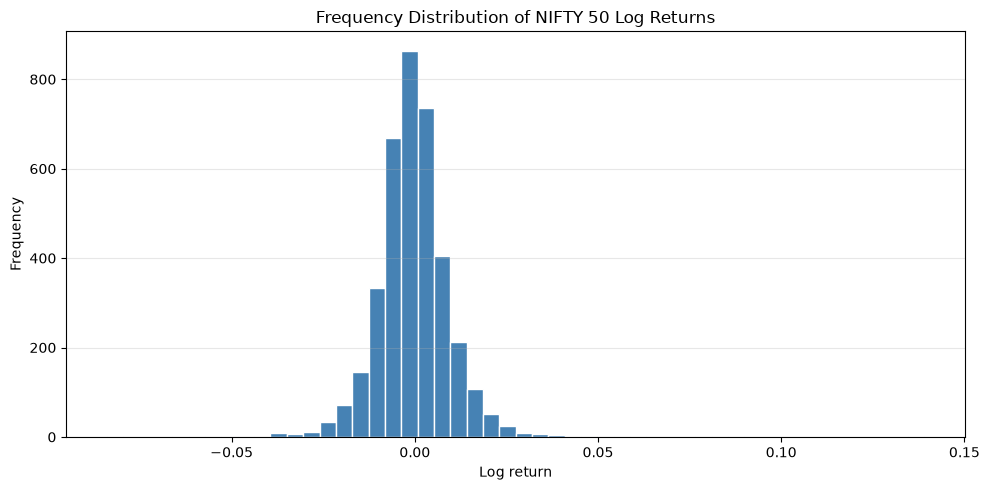

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["log_returns"], bins=50, color="steelblue", edgecolor="white")
ax.set(title="Frequency Distribution of NIFTY 50 Log Returns", xlabel="Log return", ylabel="Frequency")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

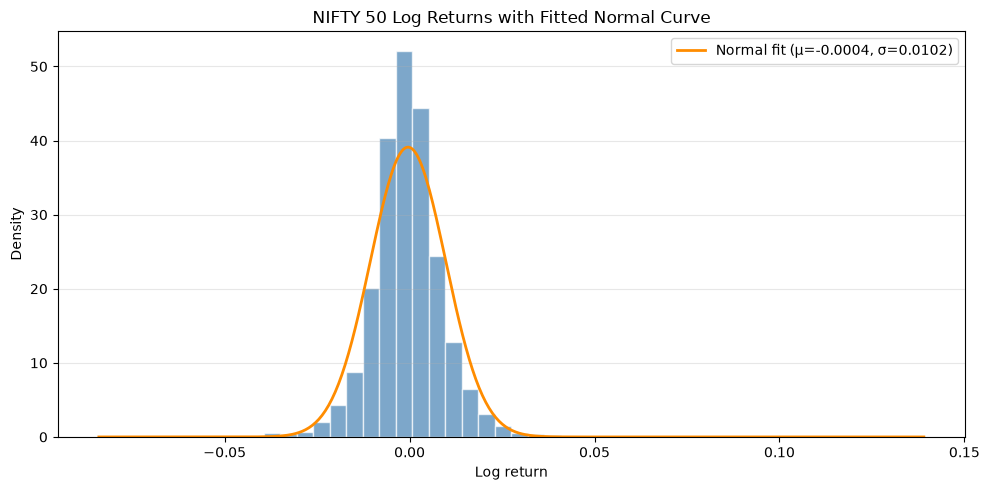

In [4]:
returns = df["log_returns"]
mu, sigma = returns.mean(), returns.std(ddof=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(returns, bins=50, density=True, color="steelblue", edgecolor="white", alpha=0.7)
x = np.linspace(returns.min(), returns.max(), 500)
normal_curve = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
ax.plot(x, normal_curve, color="darkorange", linewidth=2, label=f"Normal fit (μ={mu:.4f}, σ={sigma:.4f})")

ax.set(title="NIFTY 50 Log Returns with Fitted Normal Curve",
    xlabel="Log return", ylabel="Density")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
from statistics import NormalDist

alpha = 0.01
z = NormalDist().inv_cdf(alpha)
phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

var_99 = -(mu + sigma * z)
cvar_99 = -(mu - sigma * phi / alpha)

print(f"99% VaR for Normal Distribution:  {var_99:.2%}")
print(f"99% CVaR for Normal Distribution: {cvar_99:.2%}")

99% VaR for Normal Distribution:  2.41%
99% CVaR for Normal Distribution: 2.76%


In [6]:
historical_cutoff = returns.quantile(alpha)
var_99_historical = -historical_cutoff
cvar_99_historical = -returns[returns <= historical_cutoff].mean()

print(f"Historical 99% VaR:  {var_99_historical:.2%}")
print(f"Historical 99% CVaR: {cvar_99_historical:.2%}")

Historical 99% VaR:  2.53%
Historical 99% CVaR: 3.49%


In [7]:
from scipy.stats import t

df_t, loc_t, scale_t = t.fit(returns)
q_t = t.ppf(alpha, df_t)

var_t = -(loc_t + scale_t * q_t)

# Expected shortfall for the lower tail of a Student's t distribution
cvar_t = -(
    loc_t
    - scale_t
    * ((df_t + q_t**2) / (df_t - 1))
    * t.pdf(q_t, df_t)
    / alpha
)

print(f"Fitted degrees of freedom: {df_t:.2f}")
print(f"Student's t VaR at {1 - alpha:.1%}:  {var_t:.2%}")
print(f"Student's t CVaR at {1 - alpha:.1%}: {cvar_t:.2%}")

Fitted degrees of freedom: 2.38
Student's t VaR at 99.0%:  3.63%
Student's t CVaR at 99.0%: 6.28%


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genpareto

class StandalonePOT:
    """
    Implements the Peaks Over Threshold (POT) method directly on raw returns 
    WITHOUT GARCH volatility filtering (Baseline Model).
    """
    def __init__(self, returns: pd.Series):
        self.returns = returns.dropna().values
        # Step 1: Invert signs so losses become positive numbers
        self.losses = -self.returns
        self.u = None
        self.exceedances = None
        self.xi = None
        self.beta = None

    def fit_gpd(self, u_quantile: float = 0.90):
        """
        Selects threshold u based on loss percentile and fits GPD via MLE.
        """
        # Step 2: Threshold is a positive number (e.g., 90th percentile of losses)
        self.u = np.quantile(self.losses, u_quantile)
        
        # Step 3: Extract positive exceedances where Loss > u
        self.exceedances = self.losses[self.losses > self.u] - self.u
        
        # Step 4: Fit GPD (floc=0 fixes location parameter to 0)
        self.xi, _, self.beta = genpareto.fit(self.exceedances, floc=0)
        return self

    def calculate_static_risk_metrics(self, alpha: float = 0.01):
        """
        Calculates STATIC VaR and CVaR at confidence level (1 - alpha).
        Note: These metrics do NOT update daily because there is no GARCH term.
        """
        if self.xi is None or self.beta is None:
            raise ValueError("Run fit_gpd() first.")

        n = len(self.losses)
        N_u = len(self.exceedances)

        # Static EVT VaR formula on raw returns
        var_static = self.u + (self.beta / self.xi) * (((n / N_u) * alpha)**(-self.xi) - 1)
        
        # Static EVT CVaR (Expected Shortfall) formula
        cvar_static = (var_static / (1 - self.xi)) + ((self.beta - self.xi * self.u) / (1 - self.xi))

        return {
            "threshold_u": self.u,
            "tail_index_xi": self.xi,
            "scale_beta": self.beta,
            f"Static_VaR_{int((1-alpha)*100)}%": var_static,
            f"Static_CVaR_{int((1-alpha)*100)}%": cvar_static
        }

# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    # Simulate 2,500 days of daily returns
    raw_returns = pd.Series(np.random.laplace(loc=0.0001, scale=0.012, size=2500))

    # Baseline Model: POT directly on raw returns
    baseline_pot = StandalonePOT(raw_returns)
    baseline_pot.fit_gpd(u_quantile=0.90)
    baseline_metrics = baseline_pot.calculate_static_risk_metrics(alpha=0.001)

    print("=== BASELINE MODEL: Standalone POT (No GARCH) ===")
    for key, val in baseline_metrics.items():
        print(f"{key:20s}: {val:.6f}")

=== BASELINE MODEL: Standalone POT (No GARCH) ===
threshold_u         : 0.019969
tail_index_xi       : -0.164289
scale_beta          : 0.012180
Static_VaR_99%      : 0.059316
Static_CVaR_99%     : 0.064226


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genpareto

class StandalonePOT:
    """
    Implements the Peaks Over Threshold (POT) method directly on raw returns 
    WITHOUT GARCH volatility filtering (Baseline Model).
    """
    def __init__(self, returns: pd.Series):
        self.returns = returns.dropna().values
        # Step 1: Invert signs so losses become positive numbers
        self.losses = -self.returns
        self.u = None
        self.exceedances = None
        self.xi = None
        self.beta = None

    def fit_gpd(self, u_quantile: float = 0.90):
        """
        Selects threshold u based on loss percentile and fits GPD via MLE.
        """
        # Step 2: Threshold is a positive number (e.g., 90th percentile of losses)
        self.u = np.quantile(self.losses, u_quantile)
        
        # Step 3: Extract positive exceedances where Loss > u
        self.exceedances = self.losses[self.losses > self.u] - self.u
        
        # Step 4: Fit GPD (floc=0 fixes location parameter to 0)
        self.xi, _, self.beta = genpareto.fit(self.exceedances, floc=0)
        return self

    def calculate_static_risk_metrics(self, alpha: float = 0.01):
        """
        Calculates STATIC VaR and CVaR at confidence level (1 - alpha).
        Note: These metrics do NOT update daily because there is no GARCH term.
        """
        if self.xi is None or self.beta is None:
            raise ValueError("Run fit_gpd() first.")

        n = len(self.losses)
        N_u = len(self.exceedances)

        # Static EVT VaR formula on raw returns
        var_static = self.u + (self.beta / self.xi) * (((n / N_u) * alpha)**(-self.xi) - 1)
        
        # Static EVT CVaR (Expected Shortfall) formula
        cvar_static = (var_static / (1 - self.xi)) + ((self.beta - self.xi * self.u) / (1 - self.xi))

        return {
            "threshold_u": self.u,
            "tail_index_xi": self.xi,
            "scale_beta": self.beta,
            f"Static_VaR_{int((1-alpha)*100)}%": var_static,
            f"Static_CVaR_{int((1-alpha)*100)}%": cvar_static
        }

# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    np.random.seed(42)
    # Simulate 2,500 days of daily returns
    raw_returns = pd.Series(np.random.laplace(loc=0.0001, scale=0.012, size=2500))

    # Baseline Model: POT directly on raw returns
    baseline_pot = StandalonePOT(raw_returns)
    baseline_pot.fit_gpd(u_quantile=0.90)
    baseline_metrics = baseline_pot.calculate_static_risk_metrics(alpha=0.001)

    print("=== BASELINE MODEL: Standalone POT (No GARCH) ===")
    for key, val in baseline_metrics.items():
        print(f"{key:20s}: {val:.6f}")

=== BASELINE MODEL: Standalone POT (No GARCH) ===
threshold_u         : 0.019969
tail_index_xi       : -0.164289
scale_beta          : 0.012180
Static_VaR_99%      : 0.059316
Static_CVaR_99%     : 0.064226


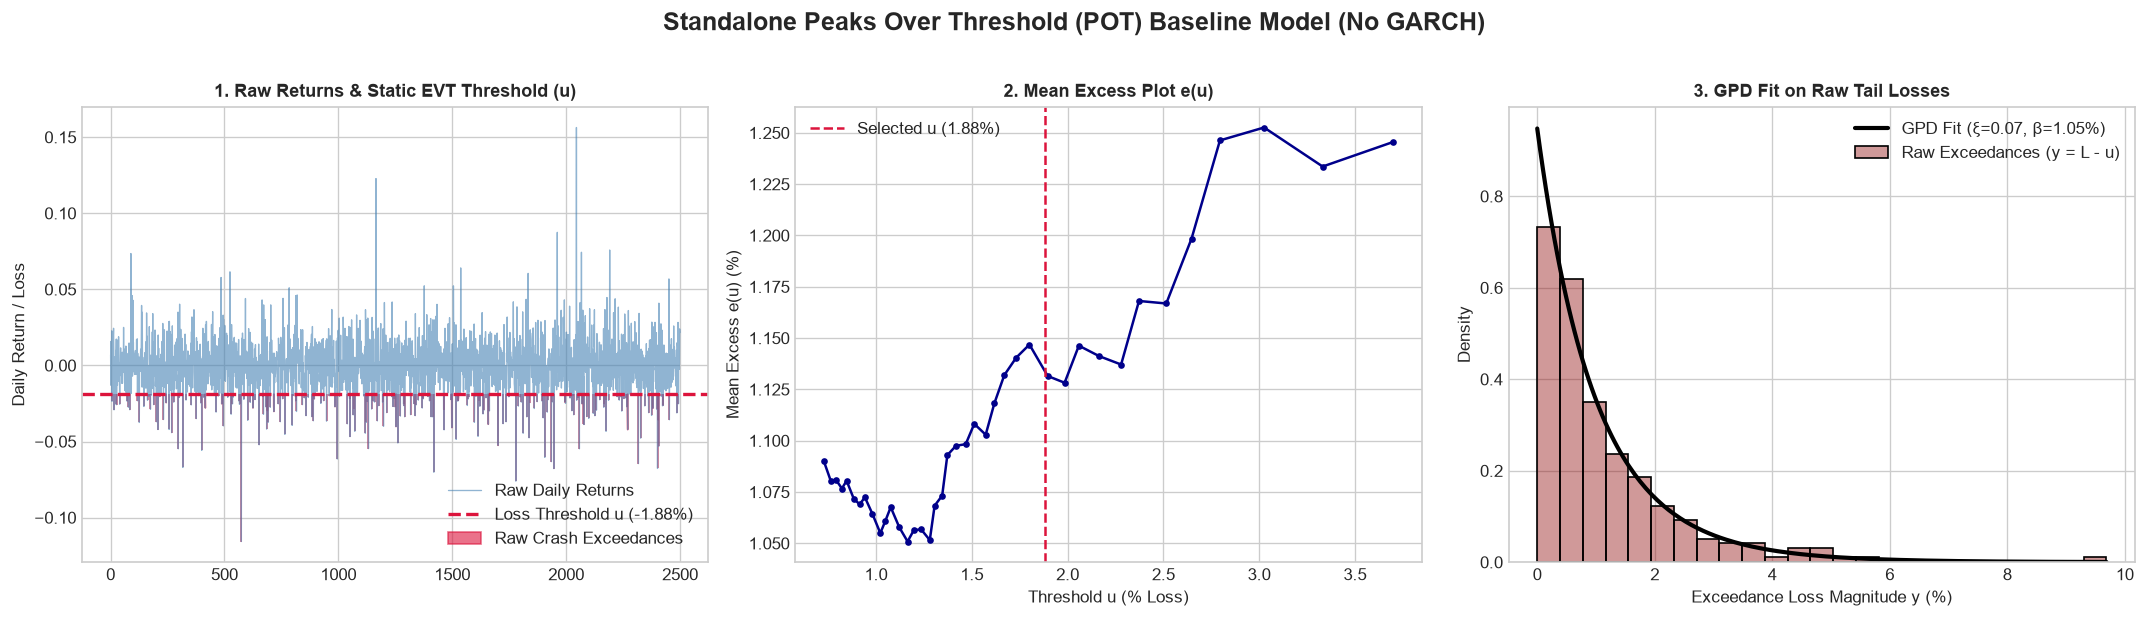

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import genpareto

# Set clean aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)
fig.suptitle('Standalone Peaks Over Threshold (POT) Baseline Model (No GARCH)', fontsize=15, fontweight='bold', y=1.02)

# -----------------------------------------------------------------------------
# 1. Generate Raw Return Data with Heavy Tails
# -----------------------------------------------------------------------------
np.random.seed(42)
n_obs = 2500
# Simulate returns with fat-tailed Student-t distribution
raw_returns = pd.Series(np.random.standard_t(df=4, size=n_obs) * 0.012)
losses = -raw_returns.values  # Invert sign so crashes become positive loss values

# Select threshold u at 90th percentile of raw losses
u_quantile = 0.90
u = np.quantile(losses, u_quantile)
exceedances = losses[losses > u] - u

# Fit GPD directly to raw exceedances via Maximum Likelihood Estimation
xi, _, beta = genpareto.fit(exceedances, floc=0)

# -----------------------------------------------------------------------------
# Panel 1: Raw Returns Time Series & Static Loss Threshold
# -----------------------------------------------------------------------------
ax1 = axes[0]
ax1.plot(raw_returns, color='steelblue', alpha=0.6, linewidth=0.8, label='Raw Daily Returns')
ax1.axhline(-u, color='crimson', linestyle='--', linewidth=2, label=f'Loss Threshold u (-{u*100:.2f}%)')
ax1.fill_between(range(n_obs), raw_returns, -u, where=(raw_returns < -u), color='crimson', alpha=0.6, label='Raw Crash Exceedances')
ax1.set_title('1. Raw Returns & Static EVT Threshold (u)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Daily Return / Loss')
ax1.legend(loc='lower right')

# -----------------------------------------------------------------------------
# Panel 2: Diagnostic Mean Excess Plot (MEP) for Threshold Selection
# -----------------------------------------------------------------------------
threshold_grid = np.quantile(losses, np.linspace(0.70, 0.98, 40))
mean_excess_values = []

for u_val in threshold_grid:
    e_vals = losses[losses > u_val] - u_val
    mean_excess_values.append(np.mean(e_vals) if len(e_vals) > 0 else 0)

ax2 = axes[1]
ax2.plot(threshold_grid * 100, np.array(mean_excess_values) * 100, marker='o', color='darkblue', markersize=3, linestyle='-')
ax2.axvline(u * 100, color='crimson', linestyle='--', label=f'Selected u ({u*100:.2f}%)')
ax2.set_title('2. Mean Excess Plot e(u)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Threshold u (% Loss)')
ax2.set_ylabel('Mean Excess e(u) (%)')
ax2.legend(loc='upper left')

# -----------------------------------------------------------------------------
# Panel 3: GPD Tail Density Fit on Raw Loss Exceedances
# -----------------------------------------------------------------------------
ax3 = axes[2]
sns.histplot(exceedances * 100, stat='density', bins=25, color='darkred', alpha=0.4, ax=ax3, label='Raw Exceedances (y = L - u)')

# Plot GPD PDF
y_grid = np.linspace(0, max(exceedances), 200)
gpd_pdf = genpareto.pdf(y_grid, c=xi, scale=beta) / 100  # Scale for percentage plot
ax3.plot(y_grid * 100, gpd_pdf, color='black', linewidth=2.5, label=f'GPD Fit (ξ={xi:.2f}, β={beta*100:.2f}%)')

ax3.set_title('3. GPD Fit on Raw Tail Losses', fontsize=11, fontweight='bold')
ax3.set_xlabel('Exceedance Loss Magnitude y (%)')
ax3.set_ylabel('Density')
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [11]:
from statsmodels.stats.diagnostic import het_arch

# Use the chronological percentage returns prepared in the GARCH cell
arch_lags = 10
garch_data = df.copy()
garch_data["Date"] = pd.to_datetime(garch_data["Date"], dayfirst=True)
garch_data["Price"] = pd.to_numeric(garch_data["Price"], errors="coerce")
garch_data = garch_data.dropna(subset=["Date", "Price"]).sort_values("Date")
returns_pct = (100 * np.log(garch_data["Price"] / garch_data["Price"].shift(1))).dropna()
mean_residuals = returns_pct.dropna() - returns_pct.dropna().mean()

lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
    mean_residuals.to_numpy(),
    nlags=arch_lags
)

print(f"Engle ARCH LM test ({arch_lags} lags)")
print(f"LM statistic: {lm_stat:.3f}, p-value: {lm_pvalue:.6g}")
print(f"F statistic:  {f_stat:.3f}, p-value: {f_pvalue:.6g}")

if lm_pvalue < 0.05:
    print("Reject the null: evidence of ARCH effects supports modeling time-varying volatility with GARCH.")
else:
    print("Do not reject the null: this test provides insufficient evidence of ARCH effects.")

Engle ARCH LM test (10 lags)
LM statistic: 919.658, p-value: 3.73887e-191
F statistic:  121.978, p-value: 2.50876e-220
Reject the null: evidence of ARCH effects supports modeling time-varying volatility with GARCH.


c:\Users\adity.ROYALIDEAPADPRO\Desktop\Portfolio risk analysi\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [12]:
from arch import arch_model
from scipy.stats import genpareto

# Rebuild returns in chronological order before fitting GARCH
garch_data = df.copy()
garch_data["Date"] = pd.to_datetime(garch_data["Date"], dayfirst=True)
garch_data["Price"] = pd.to_numeric(garch_data["Price"], errors="coerce")
garch_data = garch_data.dropna(subset=["Date", "Price"]).sort_values("Date")
returns_pct = (100 * np.log(garch_data["Price"] / garch_data["Price"].shift(1))).dropna()

# Fit GARCH(1,1) with Student-t innovations
garch_fit = arch_model(
    returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False
).fit(disp="off")

# Fit a GPD to the upper tail of standardized losses
standardized_residuals = (
    garch_fit.resid / garch_fit.conditional_volatility
).dropna()
standardized_losses = -standardized_residuals.to_numpy()

threshold = np.quantile(standardized_losses, 0.90)
exceedances_gpd = standardized_losses[standardized_losses > threshold] - threshold
xi_gpd, _, beta_gpd = genpareto.fit(exceedances_gpd, floc=0)

# EVT quantile and expected shortfall for standardized losses
tail_probability = len(exceedances_gpd) / len(standardized_losses)

if alpha >= tail_probability:
    raise ValueError("alpha must be smaller than the probability of exceeding the GPD threshold.")

if abs(xi_gpd) < 1e-8:
    evt_var_z = threshold + beta_gpd * np.log(tail_probability / alpha)
else:
    evt_var_z = threshold + (beta_gpd / xi_gpd) * (
        (tail_probability / alpha) ** xi_gpd - 1
    )

evt_es_z = (
    (evt_var_z + beta_gpd - xi_gpd * threshold) / (1 - xi_gpd)
    if xi_gpd < 1
    else np.inf
)

# One-step-ahead GARCH volatility and mean, in percentage-return units
forecast = garch_fit.forecast(horizon=1, reindex=False)
next_mean_pct = forecast.mean.iloc[-1, 0]
next_vol_pct = np.sqrt(forecast.variance.iloc[-1, 0])

# Convert the standardized EVT tail estimates into return-loss risk
var_pct = next_vol_pct * evt_var_z - next_mean_pct
es_pct = next_vol_pct * evt_es_z - next_mean_pct

print(f"GARCH next-day volatility: {next_vol_pct:.3f}%")
print(f"GPD shape (xi): {xi_gpd:.4f}")
print(f"GPD scale (beta): {beta_gpd:.4f}")
print(f"EVT VaR at {1 - alpha:.1%}: {var_pct:.3f}%")
print(f"EVT expected shortfall at {1 - alpha:.1%}: {es_pct:.3f}%")

GARCH next-day volatility: 0.825%
GPD shape (xi): 0.0347
GPD scale (beta): 0.6278
EVT VaR at 99.0%: 2.224%
EVT expected shortfall at 99.0%: 2.806%


In [13]:
from statsmodels.stats.diagnostic import acorr_ljungbox

std_resid = (
    garch_fit.resid / garch_fit.conditional_volatility
).dropna()

lags = [10, 20]

print("Ljung–Box test: standardized residuals")
display(acorr_ljungbox(std_resid, lags=lags, return_df=True))

print("Ljung–Box test: squared standardized residuals")
display(acorr_ljungbox(std_resid**2, lags=lags, return_df=True))

Ljung–Box test: standardized residuals


,lb_stat,lb_pvalue
10,16.264322,0.092312
20,21.807764,0.351032


Ljung–Box test: squared standardized residuals


,lb_stat,lb_pvalue
10,16.762477,0.079788
20,25.802691,0.172428


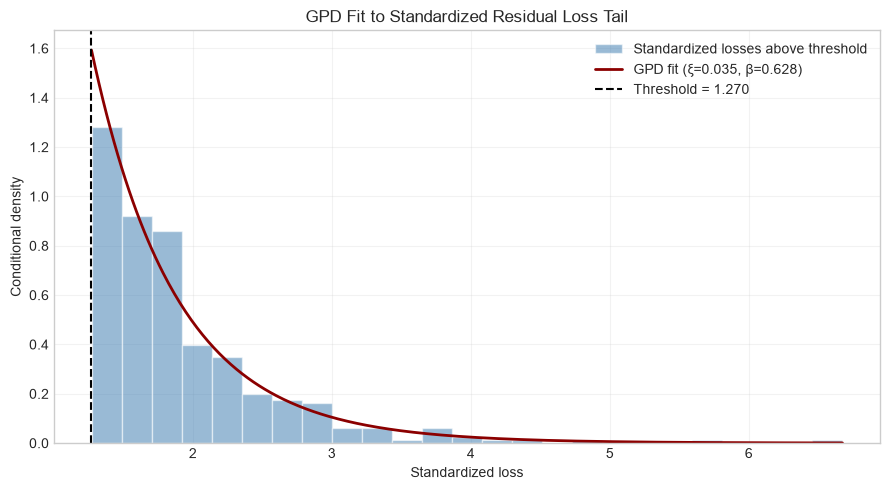

In [14]:
tail_losses = standardized_losses[standardized_losses > threshold]
x_grid = np.linspace(threshold, tail_losses.max(), 400)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    tail_losses,
    bins=25,
    density=True,
    alpha=0.55,
    color="steelblue",
    edgecolor="white",
    label="Standardized losses above threshold",
)
ax.plot(
    x_grid,
    genpareto.pdf(x_grid - threshold, c=xi_gpd, loc=0, scale=beta_gpd),
    color="darkred",
    linewidth=2,
    label=f"GPD fit (ξ={xi_gpd:.3f}, β={beta_gpd:.3f})",
)
ax.axvline(threshold, color="black", linestyle="--", label=f"Threshold = {threshold:.3f}")
ax.set(
    title="GPD Fit to Standardized Residual Loss Tail",
    xlabel="Standardized loss",
    ylabel="Conditional density",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [15]:
from scipy.stats import chi2

def kupiec_pof(actual_returns, var_loss, alpha):
    """Kupiec unconditional-coverage test; VaR and returns must use matching units."""
    actual = np.asarray(actual_returns, dtype=float)
    var = np.asarray(var_loss, dtype=float)

    if var.ndim == 0:
        var = np.full(actual.shape, var)

    valid = np.isfinite(actual) & np.isfinite(var)
    actual, var = actual[valid], var[valid]
    n = len(actual)
    exceptions = int(np.sum(-actual > var))

    if n == 0:
        raise ValueError("No valid observations for the backtest.")

    p_hat = exceptions / n

    def log_term(count, probability):
        return count * np.log(probability) if count else 0.0

    log_likelihood_null = (
        log_term(exceptions, alpha)
        + log_term(n - exceptions, 1 - alpha)
    )
    log_likelihood_unrestricted = (
        log_term(exceptions, p_hat)
        + log_term(n - exceptions, 1 - p_hat)
    )

    lr_stat = max(0.0, -2 * (log_likelihood_null - log_likelihood_unrestricted))
    return exceptions, n, p_hat, lr_stat, chi2.sf(lr_stat, df=1)


# Distribution-based VaRs (loss units match `returns`, which is decimal).
var_normal = -(mu + sigma * NormalDist().inv_cdf(alpha))
var_historical = -returns.quantile(alpha)
var_student_t = -(loc_t + scale_t * t.ppf(alpha, df_t))

models = {
    "Normal": (returns, var_normal),
    "Historical": (returns, var_historical),
    "Student-t": (returns, var_student_t),
}

# Standalone POT refitted to observed NIFTY returns (not the simulated sample).
observed_losses = -returns.dropna().to_numpy()
pot_u = np.quantile(observed_losses, 0.90)
pot_exceedances = observed_losses[observed_losses > pot_u] - pot_u
pot_xi, _, pot_beta = genpareto.fit(pot_exceedances, floc=0)
pot_tail_probability = len(pot_exceedances) / len(observed_losses)

if alpha >= pot_tail_probability:
    raise ValueError("alpha must be below the POT threshold exceedance probability.")

if abs(pot_xi) < 1e-8:
    var_pot = pot_u + pot_beta * np.log(pot_tail_probability / alpha)
else:
    var_pot = pot_u + (pot_beta / pot_xi) * (
        (pot_tail_probability / alpha) ** pot_xi - 1
    )

models["Standalone POT (refit on NIFTY)"] = (returns, var_pot)

# In-sample conditional GARCH-EVT VaR (percentage-return units).
garch_vol = garch_fit.conditional_volatility
garch_mean = garch_fit.params.get("mu", 0.0)
var_garch_evt = garch_vol * evt_var_z - garch_mean
models["GARCH-EVT (in-sample)"] = (returns_pct, var_garch_evt)

print(f"Kupiec POF test at {1 - alpha:.1%} confidence (alpha={alpha:g})")
print(f"{'Model':34s} {'Exceptions':>12s} {'Rate':>10s} {'LR':>10s} {'p-value':>12s}")

for name, (actual, var_loss) in models.items():
    exceptions, n, rate, lr_stat, p_value = kupiec_pof(actual, var_loss, alpha)
    print(
        f"{name:34s} {exceptions:>5d}/{n:<6d} "
        f"{rate:>9.3%} {lr_stat:>10.3f} {p_value:>12.4g}"
    )

Kupiec POF test at 99.0% confidence (alpha=0.01)
Model                                Exceptions       Rate         LR      p-value
Normal                                45/3715      1.211%      1.570       0.2103
Historical                            38/3715      1.023%      0.019       0.8889
Student-t                             12/3715      0.323%     23.350     1.35e-06
Standalone POT (refit on NIFTY)       31/3715      0.834%      1.090       0.2965
GARCH-EVT (in-sample)                 36/3714      0.969%      0.036       0.8501


In [16]:
def christoffersen_independence(actual_returns, var_loss):
    """Christoffersen test of independence for a sequence of VaR exceptions."""
    if isinstance(actual_returns, pd.Series) and isinstance(var_loss, pd.Series):
        actual_returns, var_loss = actual_returns.align(var_loss, join="inner")

    actual = np.asarray(actual_returns, dtype=float)
    var = np.asarray(var_loss, dtype=float)

    if var.ndim == 0:
        var = np.full(actual.shape, var)

    valid = np.isfinite(actual) & np.isfinite(var)
    exceptions = (-actual[valid] > var[valid]).astype(int)

    if len(exceptions) < 2:
        raise ValueError("At least two valid observations are required.")

    previous, current = exceptions[:-1], exceptions[1:]
    n00 = int(np.sum((previous == 0) & (current == 0)))
    n01 = int(np.sum((previous == 0) & (current == 1)))
    n10 = int(np.sum((previous == 1) & (current == 0)))
    n11 = int(np.sum((previous == 1) & (current == 1)))

    def log_binomial_likelihood(successes, trials):
        if trials == 0:
            return 0.0
        p = successes / trials
        terms = []
        if successes:
            terms.append(successes * np.log(p))
        if trials - successes:
            terms.append((trials - successes) * np.log1p(-p))
        return sum(terms)

    # Under independence, the exception probability is the same after either state.
    total_transitions = n00 + n01 + n10 + n11
    total_exceptions = n01 + n11
    log_likelihood_null = log_binomial_likelihood(
        total_exceptions, total_transitions
    )

    # Under the alternative, transition probabilities depend on the previous state.
    log_likelihood_alt = (
        log_binomial_likelihood(n01, n00 + n01)
        + log_binomial_likelihood(n11, n10 + n11)
    )

    lr_stat = max(0.0, 2 * (log_likelihood_alt - log_likelihood_null))
    p_value = chi2.sf(lr_stat, df=1)

    return n00, n01, n10, n11, lr_stat, p_value


print("Christoffersen independence test")
print(f"{'Model':34s} {'n00':>7s} {'n01':>7s} {'n10':>7s} {'n11':>7s} {'LR':>9s} {'p-value':>11s}")

for name, (actual, var_loss) in models.items():
    n00, n01, n10, n11, lr_stat, p_value = christoffersen_independence(
        actual, var_loss
    )
    print(
        f"{name:34s} {n00:7d} {n01:7d} {n10:7d} {n11:7d} "
        f"{lr_stat:9.3f} {p_value:11.4g}"
    )

Christoffersen independence test
Model                                  n00     n01     n10     n11        LR     p-value
Normal                                3628      41      41       4     9.588    0.001959
Historical                            3641      35      35       3     7.411    0.006484
Student-t                             3691      11      11       1     4.737     0.02953
Standalone POT (refit on NIFTY)       3654      29      29       2     4.900     0.02686
GARCH-EVT (in-sample)                 3641      36      36       0     0.705      0.4011


Out-of-sample period: 2022-10-06 to 2026-10-06
Observations: 992
VaR confidence: 99.00%
Exceptions: 7 (observed rate: 0.706%; expected: 9.9)
Kupiec POF: LR=0.968, p-value=0.3253
Christoffersen independence: LR=0.100, p-value=0.7523


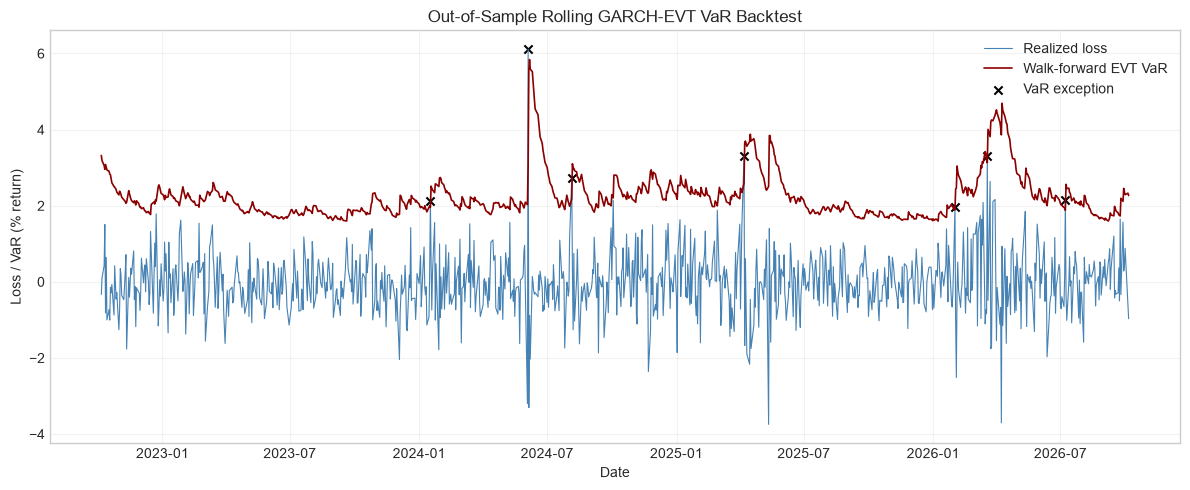

,actual_return_pct,actual_loss_pct,VaR_pct,GARCH_vol_pct,GPD_xi,exception
Date,,,,,,
2022-10-06,0.332312,-0.332312,3.319781,1.200346,0.028901,False
2022-10-07,-0.099000,0.099000,3.184771,1.152737,0.028901,False
2022-10-10,-0.426270,0.426270,3.055286,1.107077,0.028901,False
2022-10-11,-1.504504,1.504504,2.955899,1.072030,0.028901,False
2022-10-12,0.821240,-0.821240,3.083113,1.116890,0.028901,False


In [17]:
# Rolling walk-forward GARCH-EVT backtest
# Uses existing: df, alpha, arch_model, genpareto, kupiec_pof,
# christoffersen_independence, pd, np, and plt.

# Prepare chronologically ordered percentage returns with dates as the index.
garch_data = df.copy()
garch_data["Date"] = pd.to_datetime(garch_data["Date"], dayfirst=True, errors="coerce")
garch_data["Price"] = pd.to_numeric(garch_data["Price"], errors="coerce")
garch_data = (
    garch_data.dropna(subset=["Date", "Price"])
    .sort_values("Date")
    .drop_duplicates(subset="Date", keep="last")
)

prices = garch_data.set_index("Date")["Price"]
returns_oos = (100 * np.log(prices / prices.shift(1))).dropna()

# Configuration
BACKTEST_ALPHA = alpha           # Existing notebook value: 0.001 (99.9% VaR)
ROLLING_WINDOW = 252 * 10         # 10 years of trading days
REFIT_EVERY = 21                  # Re-estimate approximately monthly
TEST_START = returns_oos.index.max() - pd.DateOffset(years=4)

test_positions = np.flatnonzero(returns_oos.index >= TEST_START)
if len(test_positions) == 0:
    raise ValueError("No observations found in the selected out-of-sample period.")

oos_rows = []
model_state = None

for step, i in enumerate(test_positions):
    # Refit using only observations strictly before the date being forecast.
    if model_state is None or step % REFIT_EVERY == 0:
        train = returns_oos.iloc[max(0, i - ROLLING_WINDOW):i]

        if len(train) < 500:
            raise ValueError(f"Insufficient training observations before {returns_oos.index[i]}.")

        fit = arch_model(
            train,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="t",
            rescale=False,
        ).fit(disp="off")

        # Fit a GPD to the training sample's standardized loss tail.
        train_std_losses = (
            -(fit.resid / fit.conditional_volatility)
        ).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()

        threshold_oos = np.quantile(train_std_losses, 0.90)
        exceedances_oos = train_std_losses[train_std_losses > threshold_oos] - threshold_oos

        if len(exceedances_oos) < 10:
            raise ValueError("Too few threshold exceedances to fit the GPD reliably.")

        xi_oos, _, beta_oos = genpareto.fit(exceedances_oos, floc=0)
        tail_prob_oos = len(exceedances_oos) / len(train_std_losses)

        if BACKTEST_ALPHA >= tail_prob_oos:
            raise ValueError(
                f"alpha={BACKTEST_ALPHA:g} must be below the GPD tail probability "
                f"({tail_prob_oos:.4g})."
            )

        if abs(xi_oos) < 1e-8:
            evt_var_z_oos = threshold_oos + beta_oos * np.log(
                tail_prob_oos / BACKTEST_ALPHA
            )
        else:
            evt_var_z_oos = threshold_oos + (beta_oos / xi_oos) * (
                (tail_prob_oos / BACKTEST_ALPHA) ** xi_oos - 1
            )

        params = fit.params
        mu_oos = float(params.get("mu", 0.0))
        omega_oos = float(params["omega"])
        arch_alpha = float(params["alpha[1]"])
        garch_beta = float(params["beta[1]"])

        # One-step-ahead conditional variance forecast.
        forecast = fit.forecast(horizon=1, reindex=False)
        variance_forecast = float(forecast.variance.iloc[-1, 0])

        model_state = {
            "mu": mu_oos,
            "omega": omega_oos,
            "arch_alpha": arch_alpha,
            "garch_beta": garch_beta,
            "evt_var_z": float(evt_var_z_oos),
            "variance_forecast": variance_forecast,
            "xi": float(xi_oos),
        }

    # Forecast VaR before observing this day's return.
    sigma_forecast = np.sqrt(max(model_state["variance_forecast"], 0.0))
    var_loss_pct = sigma_forecast * model_state["evt_var_z"] - model_state["mu"]
    actual_return_pct = float(returns_oos.iloc[i])

    oos_rows.append({
        "Date": returns_oos.index[i],
        "actual_return_pct": actual_return_pct,
        "actual_loss_pct": -actual_return_pct,
        "VaR_pct": var_loss_pct,
        "GARCH_vol_pct": sigma_forecast,
        "GPD_xi": model_state["xi"],
    })

    # Update next day's variance using today's now-observed return.
    residual = actual_return_pct - model_state["mu"]
    model_state["variance_forecast"] = (
        model_state["omega"]
        + model_state["arch_alpha"] * residual**2
        + model_state["garch_beta"] * model_state["variance_forecast"]
    )

oos_backtest = pd.DataFrame(oos_rows).set_index("Date")
oos_backtest["exception"] = oos_backtest["actual_loss_pct"] > oos_backtest["VaR_pct"]

print(f"Out-of-sample period: {oos_backtest.index.min().date()} to {oos_backtest.index.max().date()}")
print(f"Observations: {len(oos_backtest)}")
print(f"VaR confidence: {1 - BACKTEST_ALPHA:.2%}")
print(f"Exceptions: {oos_backtest['exception'].sum()} "
      f"(observed rate: {oos_backtest['exception'].mean():.3%}; "
      f"expected: {len(oos_backtest) * BACKTEST_ALPHA:.1f})")

# Backtest tests; these functions were defined in earlier notebook cells.
exceptions, n, exception_rate, kupiec_lr, kupiec_p = kupiec_pof(
    oos_backtest["actual_return_pct"],
    oos_backtest["VaR_pct"],
    BACKTEST_ALPHA,
)
print(f"Kupiec POF: LR={kupiec_lr:.3f}, p-value={kupiec_p:.4g}")

n00, n01, n10, n11, ind_lr, ind_p = christoffersen_independence(
    oos_backtest["actual_return_pct"],
    oos_backtest["VaR_pct"],
)
print(f"Christoffersen independence: LR={ind_lr:.3f}, p-value={ind_p:.4g}")

# Plot realized losses against the one-step-ahead VaR forecasts.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(oos_backtest.index, oos_backtest["actual_loss_pct"],
        color="steelblue", linewidth=0.8, label="Realized loss")
ax.plot(oos_backtest.index, oos_backtest["VaR_pct"],
        color="darkred", linewidth=1.2, label="Walk-forward EVT VaR")
exceptions_oos = oos_backtest[oos_backtest["exception"]]
ax.scatter(exceptions_oos.index, exceptions_oos["actual_loss_pct"],
           color="black", marker="x", s=35, label="VaR exception")
ax.set(
    title="Out-of-Sample Rolling GARCH-EVT VaR Backtest",
    xlabel="Date",
    ylabel="Loss / VaR (% return)",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

oos_backtest.head()

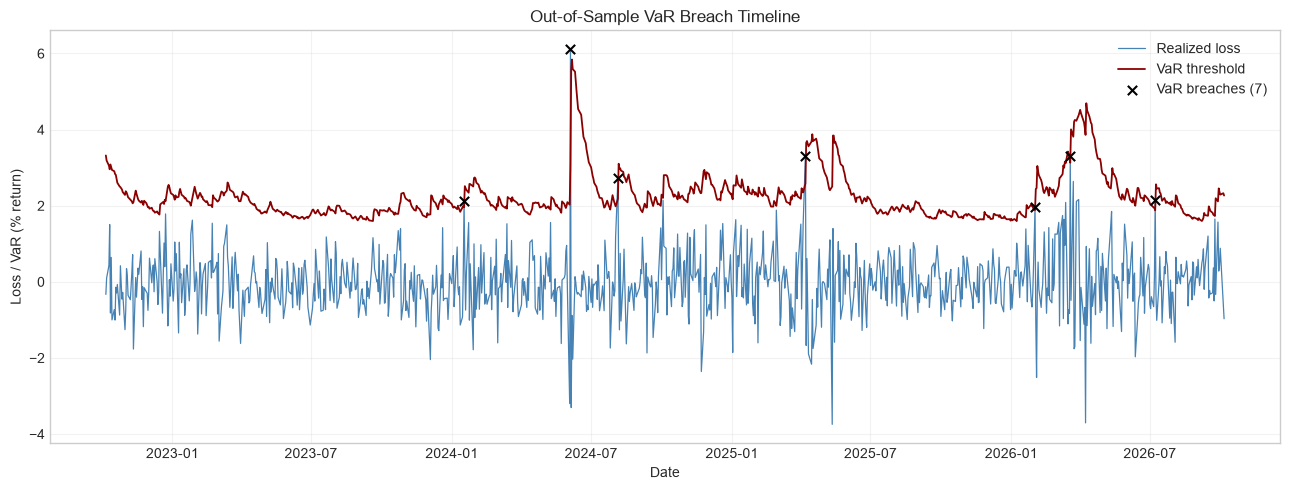

In [18]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    oos_backtest.index,
    oos_backtest["actual_loss_pct"],
    color="steelblue",
    linewidth=0.9,
    label="Realized loss",
)
ax.plot(
    oos_backtest.index,
    oos_backtest["VaR_pct"],
    color="darkred",
    linewidth=1.3,
    label="VaR threshold",
)

breaches = oos_backtest[oos_backtest["exception"]]
ax.scatter(
    breaches.index,
    breaches["actual_loss_pct"],
    color="black",
    marker="x",
    s=45,
    zorder=3,
    label=f"VaR breaches ({len(breaches)})",
)

ax.set(
    title="Out-of-Sample VaR Breach Timeline",
    xlabel="Date",
    ylabel="Loss / VaR (% return)",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

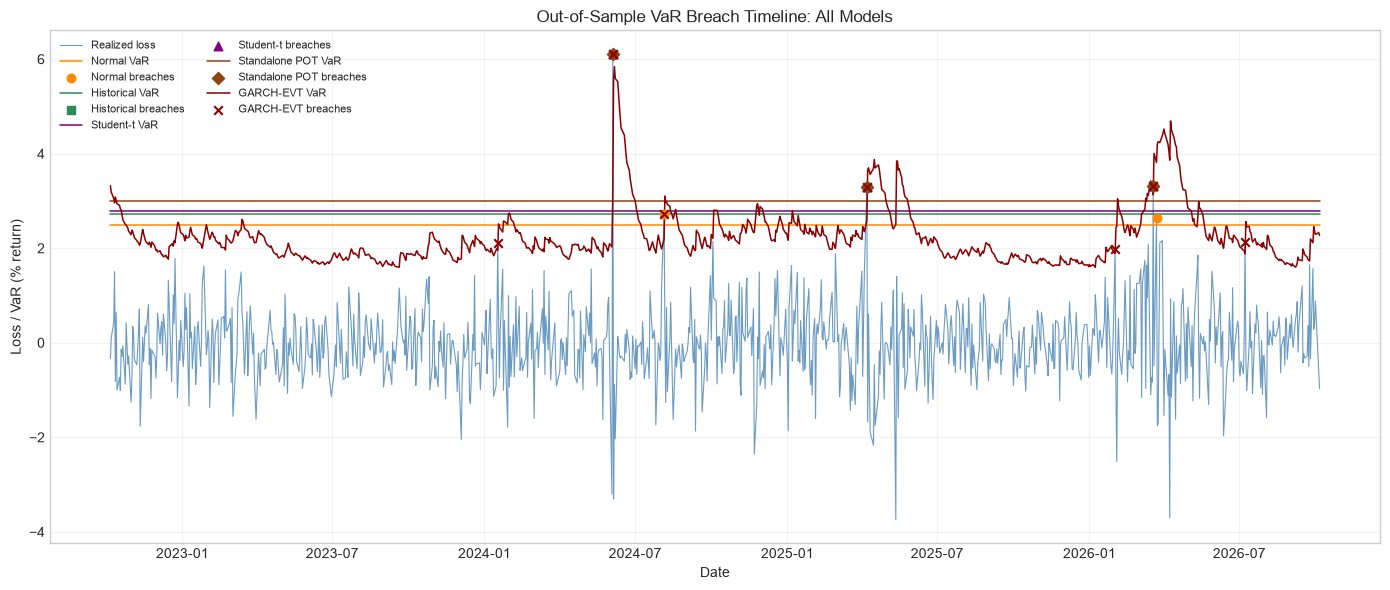

In [19]:
# Fit static benchmark VaRs using only pre-test returns.
train_returns_pct = returns_oos.loc[returns_oos.index < TEST_START]

if train_returns_pct.empty:
    raise ValueError("No pre-test returns are available to fit the benchmark models.")

static_var_pct = {
    "Normal": -(
        train_returns_pct.mean()
        + train_returns_pct.std(ddof=1) * NormalDist().inv_cdf(BACKTEST_ALPHA)
    ),
    "Historical": -train_returns_pct.quantile(BACKTEST_ALPHA),
}

df_t_oos, loc_t_oos, scale_t_oos = t.fit(train_returns_pct)
static_var_pct["Student-t"] = -(
    loc_t_oos + scale_t_oos * t.ppf(BACKTEST_ALPHA, df_t_oos)
)

# Fit standalone POT to pre-test losses.
train_losses_pct = -train_returns_pct.to_numpy()
pot_threshold = np.quantile(train_losses_pct, 0.90)
pot_exceedances = train_losses_pct[train_losses_pct > pot_threshold] - pot_threshold
pot_xi, _, pot_beta = genpareto.fit(pot_exceedances, floc=0)
pot_tail_probability = len(pot_exceedances) / len(train_losses_pct)

if BACKTEST_ALPHA >= pot_tail_probability:
    raise ValueError("BACKTEST_ALPHA must be below the POT threshold exceedance probability.")

if abs(pot_xi) < 1e-8:
    static_var_pct["Standalone POT"] = (
        pot_threshold + pot_beta * np.log(pot_tail_probability / BACKTEST_ALPHA)
    )
else:
    static_var_pct["Standalone POT"] = (
        pot_threshold
        + (pot_beta / pot_xi)
        * ((pot_tail_probability / BACKTEST_ALPHA) ** pot_xi - 1)
    )

# Add the walk-forward GARCH-EVT VaR series.
var_forecasts = {
    name: pd.Series(value, index=oos_backtest.index)
    for name, value in static_var_pct.items()
}
var_forecasts["GARCH-EVT"] = oos_backtest["VaR_pct"]

actual_loss = oos_backtest["actual_loss_pct"]
styles = {
    "Normal": ("darkorange", "o"),
    "Historical": ("seagreen", "s"),
    "Student-t": ("purple", "^"),
    "Standalone POT": ("saddlebrown", "D"),
    "GARCH-EVT": ("darkred", "x"),
}

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(actual_loss.index, actual_loss, color="steelblue", linewidth=0.8,
        alpha=0.8, label="Realized loss")

for name, var_series in var_forecasts.items():
    color, marker = styles[name]
    ax.plot(var_series.index, var_series, color=color, linewidth=1.1,
            label=f"{name} VaR")
    breaches = actual_loss > var_series
    ax.scatter(
        actual_loss.index[breaches],
        actual_loss[breaches],
        color=color,
        marker=marker,
        s=38,
        zorder=3,
        label=f"{name} breaches",
    )

ax.set(
    title="Out-of-Sample VaR Breach Timeline: All Models",
    xlabel="Date",
    ylabel="Loss / VaR (% return)",
)
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [20]:
from scipy.stats import norm

# Recreate one-step-ahead rolling GARCH-EVT forecasts, now including ES.
es_rows = []
model_state = None

for step, i in enumerate(test_positions):
    if model_state is None or step % REFIT_EVERY == 0:
        train = returns_oos.iloc[max(0, i - ROLLING_WINDOW):i]

        fit = arch_model(
            train,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="t",
            rescale=False,
        ).fit(disp="off")

        train_std_losses = (
            -(fit.resid / fit.conditional_volatility)
        ).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()

        threshold_es = np.quantile(train_std_losses, 0.90)
        exceedances_es = train_std_losses[train_std_losses > threshold_es] - threshold_es

        if len(exceedances_es) < 10:
            raise ValueError("Too few exceedances to fit the GPD reliably.")

        xi_es, _, beta_es = genpareto.fit(exceedances_es, floc=0)
        tail_prob_es = len(exceedances_es) / len(train_std_losses)

        if BACKTEST_ALPHA >= tail_prob_es:
            raise ValueError("BACKTEST_ALPHA must be below the GPD exceedance probability.")
        if xi_es >= 1:
            raise ValueError("GPD shape xi >= 1: expected shortfall is not finite.")

        if abs(xi_es) < 1e-8:
            var_z_es = threshold_es + beta_es * np.log(tail_prob_es / BACKTEST_ALPHA)
        else:
            var_z_es = threshold_es + (beta_es / xi_es) * (
                (tail_prob_es / BACKTEST_ALPHA) ** xi_es - 1
            )

        es_z_es = (var_z_es + beta_es - xi_es * threshold_es) / (1 - xi_es)

        params = fit.params
        mu_es = float(params.get("mu", 0.0))
        variance_es = float(fit.forecast(horizon=1, reindex=False).variance.iloc[-1, 0])

        model_state = {
            "mu": mu_es,
            "omega": float(params["omega"]),
            "arch_alpha": float(params["alpha[1]"]),
            "garch_beta": float(params["beta[1]"]),
            "variance": variance_es,
            "var_z": float(var_z_es),
            "es_z": float(es_z_es),
        }

    sigma_es = np.sqrt(max(model_state["variance"], 0.0))
    actual_return = float(returns_oos.iloc[i])

    es_rows.append({
        "Date": returns_oos.index[i],
        "VaR_pct": sigma_es * model_state["var_z"] - model_state["mu"],
        "ES_pct": sigma_es * model_state["es_z"] - model_state["mu"],
        "actual_return_pct": actual_return,
        "actual_loss_pct": -actual_return,
    })

    # Update variance after observing this day's return.
    residual = actual_return - model_state["mu"]
    model_state["variance"] = (
        model_state["omega"]
        + model_state["arch_alpha"] * residual**2
        + model_state["garch_beta"] * model_state["variance"]
    )

es_backtest = pd.DataFrame(es_rows).set_index("Date")
es_backtest["exception"] = es_backtest["actual_loss_pct"] > es_backtest["VaR_pct"]

# ES calibration identity:
# E[(Loss - VaR) * I(Loss > VaR)] = alpha * (ES - VaR)
alpha_es = BACKTEST_ALPHA
loss = es_backtest["actual_loss_pct"].to_numpy()
var_forecast = es_backtest["VaR_pct"].to_numpy()
es_forecast = es_backtest["ES_pct"].to_numpy()
hit = (loss > var_forecast).astype(float)

calibration_residual = (
    hit * (loss - var_forecast)
    - alpha_es * (es_forecast - var_forecast)
)

# Newey-West HAC standard error for the mean calibration residual.
n = len(calibration_residual)
centered = calibration_residual - calibration_residual.mean()
max_lag = min(10, n - 1)

long_run_variance = np.dot(centered, centered) / n
for lag in range(1, max_lag + 1):
    autocov = np.dot(centered[lag:], centered[:-lag]) / n
    weight = 1 - lag / (max_lag + 1)
    long_run_variance += 2 * weight * autocov

se_mean = np.sqrt(max(long_run_variance, 0) / n)
z_stat = calibration_residual.mean() / se_mean if se_mean > 0 else np.nan
p_value = 2 * norm.sf(abs(z_stat)) if np.isfinite(z_stat) else np.nan

print(f"Observations: {n}")
print(f"VaR breaches: {int(hit.sum())} (expected about {n * alpha_es:.2f})")
print(f"Mean ES calibration residual: {calibration_residual.mean():.6f}")
print(f"HAC z-statistic: {z_stat:.3f}; two-sided p-value: {p_value:.4g}")

if hit.sum() < 10:
    print("Caution: very few breaches; the ES backtest has low power.")

Observations: 992
VaR breaches: 7 (expected about 9.92)
Mean ES calibration residual: -0.000897
HAC z-statistic: -0.286; two-sided p-value: 0.7745
Caution: very few breaches; the ES backtest has low power.


In [ ]:
# Quantile-loss comparison on the out-of-sample period
tau = 1 - BACKTEST_ALPHA

actual_loss = oos_backtest["actual_loss_pct"].rename("actual_loss")
forecast_df = pd.DataFrame(var_forecasts)

comparison = pd.concat([actual_loss, forecast_df], axis=1).dropna()
actual = comparison["actual_loss"]

# Pinball loss for the upper-tail loss quantile
quantile_losses = {}
for name in forecast_df.columns:
    error = actual - comparison[name]
    quantile_losses[name] = (tau - (error < 0).astype(float)) * error

quantile_losses = pd.DataFrame(quantile_losses)
print(f"Mean quantile loss (τ={tau:.3%}; lower is better)")
display(quantile_losses.mean().sort_values().rename("Mean quantile loss").to_frame())

# Diebold–Mariano tests against GARCH-EVT, using Newey–West HAC standard errors
benchmark = "GARCH-EVT"
if benchmark not in quantile_losses.columns:
    raise ValueError(f"{benchmark} is missing from the forecast columns.")

dm_rows = []
n = len(quantile_losses)
hac_lags = min(10, n - 1)

for name in quantile_losses.columns:
    if name == benchmark:
        continue

    difference = (
        quantile_losses[name] - quantile_losses[benchmark]
    ).to_numpy()
    mean_diff = difference.mean()
    centered = difference - mean_diff

    long_run_variance = np.dot(centered, centered) / n
    for lag in range(1, hac_lags + 1):
        autocov = np.dot(centered[lag:], centered[:-lag]) / n
        long_run_variance += 2 * (1 - lag / (hac_lags + 1)) * autocov

    standard_error = np.sqrt(max(long_run_variance, 0) / n)
    statistic = mean_diff / standard_error if standard_error > 0 else np.nan
    p_value = 2 * norm.sf(abs(statistic)) if np.isfinite(statistic) else np.nan

    dm_rows.append({
        "Model": name,
        "Mean loss difference vs GARCH-EVT": mean_diff,
        "DM statistic": statistic,
        "p-value": p_value,
    })

dm_results = pd.DataFrame(dm_rows).set_index("Model")
display(dm_results)